In [2]:
import pandas as pd


In [3]:
data=pd.read_csv("C:/Users/shrid/Downloads/mlpractice/Car.csv")

In [4]:
data


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000.0,70000.0,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000.0,50000.0,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000.0,100000.0,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000.0,46000.0,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000.0,141000.0,Diesel,Individual,Manual,Second Owner
...,...,...,...,...,...,...,...,...
4335,Hyundai i20 Magna 1.4 CRDi (Diesel),2014,409999.0,80000.0,Diesel,Individual,Manual,Second Owner
4336,Hyundai i20 Magna 1.4 CRDi,2014,409999.0,80000.0,Diesel,Individual,Manual,Second Owner
4337,Maruti 800 AC BSIII,2009,110000.0,83000.0,Petrol,Individual,Manual,Second Owner
4338,Hyundai Creta 1.6 CRDi SX Option,2016,865000.0,90000.0,Diesel,Individual,Manual,First Owner


In [5]:
data.shape

(4340, 8)

In [6]:
data.columns

Index(['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type',
       'transmission', 'owner'],
      dtype='object')

In [7]:
data.duplicated().sum()

np.int64(761)

In [8]:
data=data.drop_duplicates()

In [9]:
data.duplicated().sum()

np.int64(0)

In [10]:
data.isna().sum()

name             0
year             0
selling_price    3
km_driven        3
fuel             2
seller_type      0
transmission     2
owner            0
dtype: int64

In [11]:
data=data.copy()
data["selling_price"] = data["selling_price"].fillna(data["selling_price"].median())
data["km_driven"] = data["km_driven"].fillna(data["km_driven"].median())

data["fuel"] = data["fuel"].fillna(data["fuel"].mode()[0])
data["transmission"] = data["transmission"].fillna(data["transmission"].mode()[0])

In [12]:
data.isna().sum()

name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64

In [13]:
#### statistical  analysis

data[["year", "selling_price", "km_driven"]].mean()


year               2012.963118
selling_price    474314.099749
km_driven         69250.749371
dtype: float64

In [14]:
data[["year", "selling_price", "km_driven"]].median()

year               2013.0
selling_price    350000.0
km_driven         60104.0
dtype: float64

In [15]:
data[["year", "selling_price", "km_driven"]].mode()

,year,selling_price,km_driven
0,2017,300000.0,70000.0


In [16]:
data[["year", "selling_price", "km_driven"]].min()

year              1992.0
selling_price    20000.0
km_driven            1.0
dtype: float64

In [17]:
data[["year", "selling_price", "km_driven"]].max()

year                2020.0
selling_price    8900000.0
km_driven         806599.0
dtype: float64

In [18]:
data[["year", "selling_price", "km_driven"]].std()

year                  4.250707
selling_price    509470.897350
km_driven         47564.825450
dtype: float64

In [19]:
import matplotlib.pyplot as plt


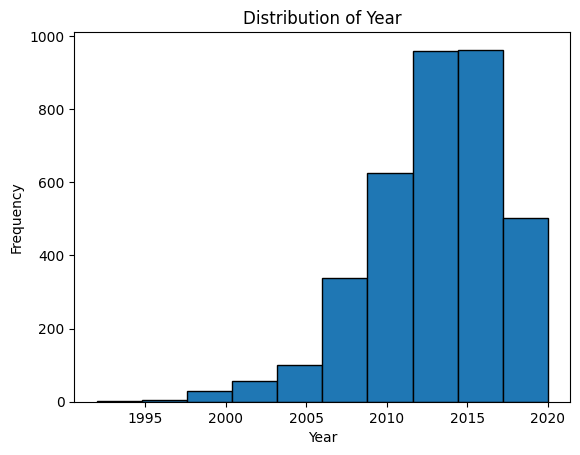

In [20]:
plt.hist(data["year"], edgecolor="black")
plt.title("Distribution of Year")
plt.xlabel("Year")
plt.ylabel("Frequency")
plt.show()

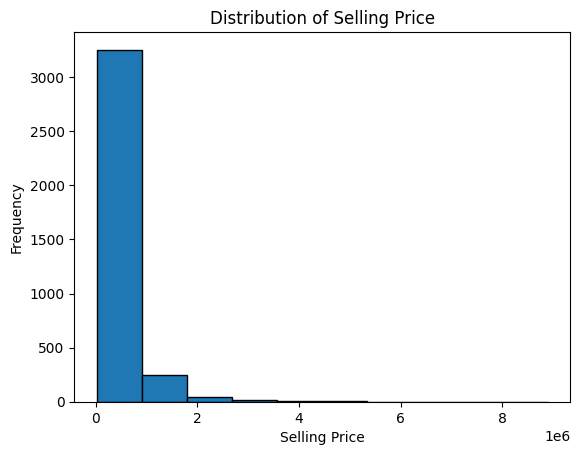

In [21]:
plt.hist(data["selling_price"], edgecolor="black")
plt.title("Distribution of Selling Price")
plt.xlabel("Selling Price")
plt.ylabel("Frequency")
plt.show()

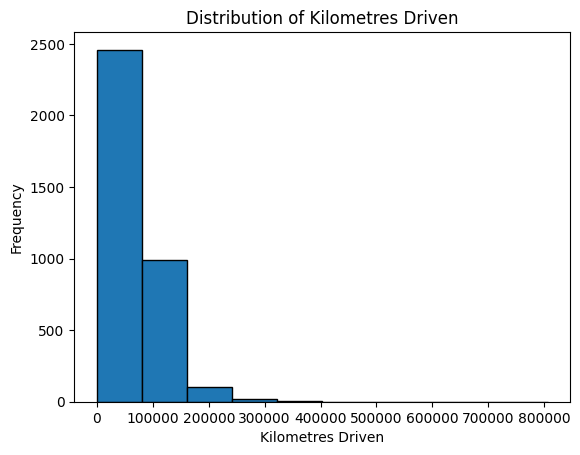

In [22]:
plt.hist(data["km_driven"],edgecolor="black")
plt.title("Distribution of Kilometres Driven")
plt.xlabel("Kilometres Driven")
plt.ylabel("Frequency")
plt.show()

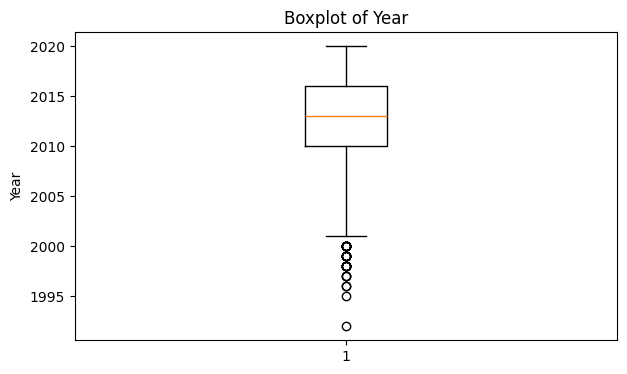

In [23]:
plt.figure(figsize=(7, 4))
plt.boxplot(data["year"])
plt.title("Boxplot of Year")
plt.ylabel("Year")
plt.show()

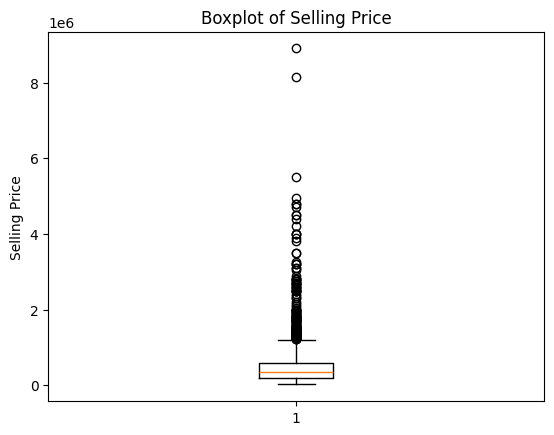

In [24]:
plt.boxplot(data["selling_price"])
plt.title("Boxplot of Selling Price")
plt.ylabel("Selling Price")
plt.show()

Text(0, 0.5, 'Kilometres Driven')

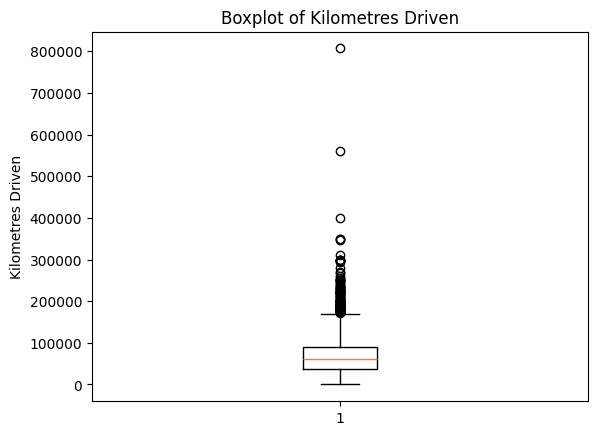

In [25]:
plt.boxplot(data["km_driven"])
plt.title("Boxplot of Kilometres Driven")
plt.ylabel("Kilometres Driven")

In [26]:
from sklearn.preprocessing import MinMaxScaler

In [27]:
scaler = MinMaxScaler()
data[['year', 'km_driven']] = scaler.fit_transform(data[['year', 'km_driven']])
data[['year', 'km_driven']].head()

,year,km_driven
0,0.535714,0.086783
1,0.535714,0.061988
2,0.714286,0.123976
3,0.892857,0.057028
4,0.785714,0.174807


In [28]:
data["seller_type"].unique()

array(['Individual', 'Dealer', 'Trustmark Dealer'], dtype=object)

In [29]:
data["fuel"].unique()

array(['Petrol', 'Diesel', 'CNG', 'LPG', 'Electric'], dtype=object)

In [30]:
data["transmission"].unique()

array(['Manual', 'Automatic'], dtype=object)

In [31]:
data["owner"].unique()

array(['First Owner', 'Second Owner', 'Fourth & Above Owner',
       'Third Owner', 'Test Drive Car'], dtype=object)

In [32]:
###encoding
from sklearn.preprocessing import LabelEncoder

In [33]:
le =LabelEncoder()
data=data.copy()
data["fuel"] = le.fit_transform(data["fuel"])
data["seller_type"] = le.fit_transform(data["seller_type"])
data["transmission"] = le.fit_transform(data["transmission"])
data["owner"] = le.fit_transform(data["owner"])

In [34]:
data

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,0.535714,60000.0,0.086783,4,1,1,0
1,Maruti Wagon R LXI Minor,0.535714,135000.0,0.061988,4,1,1,0
2,Hyundai Verna 1.6 SX,0.714286,600000.0,0.123976,1,1,1,0
3,Datsun RediGO T Option,0.892857,250000.0,0.057028,4,1,1,0
4,Honda Amaze VX i-DTEC,0.785714,450000.0,0.174807,1,1,1,2
...,...,...,...,...,...,...,...,...
4335,Hyundai i20 Magna 1.4 CRDi (Diesel),0.785714,409999.0,0.099181,1,1,1,2
4336,Hyundai i20 Magna 1.4 CRDi,0.785714,409999.0,0.099181,1,1,1,2
4337,Maruti 800 AC BSIII,0.607143,110000.0,0.102900,4,1,1,2
4338,Hyundai Creta 1.6 CRDi SX Option,0.857143,865000.0,0.111579,1,1,1,0


In [35]:
data.columns

Index(['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type',
       'transmission', 'owner'],
      dtype='object')

In [36]:
from sklearn.model_selection import train_test_split

In [37]:
x = data.drop("selling_price", axis=1)
y = data["selling_price"]

In [38]:
x

,name,year,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,0.535714,0.086783,4,1,1,0
1,Maruti Wagon R LXI Minor,0.535714,0.061988,4,1,1,0
2,Hyundai Verna 1.6 SX,0.714286,0.123976,1,1,1,0
3,Datsun RediGO T Option,0.892857,0.057028,4,1,1,0
4,Honda Amaze VX i-DTEC,0.785714,0.174807,1,1,1,2
...,...,...,...,...,...,...,...
4335,Hyundai i20 Magna 1.4 CRDi (Diesel),0.785714,0.099181,1,1,1,2
4336,Hyundai i20 Magna 1.4 CRDi,0.785714,0.099181,1,1,1,2
4337,Maruti 800 AC BSIII,0.607143,0.102900,4,1,1,2
4338,Hyundai Creta 1.6 CRDi SX Option,0.857143,0.111579,1,1,1,0


In [39]:
y

0        60000.0
1       135000.0
2       600000.0
3       250000.0
4       450000.0
          ...   
4335    409999.0
4336    409999.0
4337    110000.0
4338    865000.0
4339    225000.0
Name: selling_price, Length: 3579, dtype: float64

In [40]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [41]:
x_train.shape

(2863, 7)

In [42]:
x_test.shape

(716, 7)

In [43]:
y_train

2346     440000.0
1248     280000.0
953      390000.0
4044     285000.0
986      400000.0
          ...    
1270     310000.0
1435     290000.0
975     1770000.0
4219     500000.0
3769     200000.0
Name: selling_price, Length: 2863, dtype: float64

In [44]:
y_test

1043     400000.0
3192     271000.0
1528     220000.0
553     3800000.0
1610     450000.0
          ...    
384      250000.0
3527     550000.0
671      400000.0
2554     596000.0
862      425000.0
Name: selling_price, Length: 716, dtype: float64